# Session 2 — Preprocessing and Leakage

In Session 1 we found a duplicate row, an impossible attendance value and some missing entries in a table of 500 students. This session cleans that same table up and turns it into numbers a model can use, then shows how a model can look perfect and be useless.

**By the end of the session you should be able to:**

1. explain why every preprocessing step is fitted on the training set only;
2. build a pipeline that imputes, scales and encodes in one object;
3. spot a feature that leaks the answer, and say why the accuracy it produces can't be trusted.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The outputs are already saved in the notebook. It runs in a few seconds, and the numbers should match because the data comes from a fixed seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42


def make_students(seed=42, n=500):
    """Synthetic course data shared by Sessions 1 and 2: same seed, same rows, same planted problems."""
    rng = np.random.default_rng(seed)
    study_hours = np.clip(rng.normal(7, 3, n), 0, 20)
    attendance = np.clip(rng.normal(78, 15, n), 0, 100)
    previous_grade = np.clip(rng.normal(67, 13, n), 0, 100)
    department = rng.choice(["CS", "Engineering", "Business"], n, p=[0.45, 0.35, 0.20])
    scholarship = rng.choice(["Yes", "No"], n, p=[0.25, 0.75])
    score = 0.32 * previous_grade + 1.5 * study_hours + 0.18 * attendance + (department == "CS") * 2 + rng.normal(0, 5, n)
    df = pd.DataFrame({"student_id": [f"S{i:04d}" for i in range(n)], "study_hours": study_hours, "attendance": attendance,
                       "previous_grade": previous_grade, "department": department, "scholarship": scholarship,
                       "passed": (score >= 44).astype(int)})
    # Planted problems: missing values, one impossible attendance, one duplicated row.
    df.loc[rng.choice(n, 22, replace=False), "previous_grade"] = np.nan
    df.loc[rng.choice(n, 15, replace=False), "department"] = np.nan
    df.loc[10, "attendance"] = 140
    return pd.concat([df, df.iloc[[25]]], ignore_index=True)


df = make_students()
print("Rows as generated:", len(df))

# The two decisions from Session 1, applied before any splitting.
df = df.drop_duplicates().reset_index(drop=True)
df.loc[~df["attendance"].between(0, 100), "attendance"] = np.nan
print("Rows after dropping the duplicate:", len(df))
print()
print(df.isna().sum()[lambda s: s > 0].to_string())

Rows as generated: 501
Rows after dropping the duplicate: 500

attendance         1
previous_grade    22
department        15


## 1. The same students, cleaned

The first cell regenerates Session 1's table with the same function and seed, so it contains the same planted problems. Before splitting, we apply the two decisions we made in Session 1: drop the duplicated row (501 rows become 500) and mark the 140% attendance as missing.

That leaves three columns with gaps: 1 attendance value, 22 previous grades and 15 departments. We don't fill them in yet, because *how* to fill them in depends on the training data, and we haven't split it.

In [2]:
numeric_features = ["study_hours", "attendance", "previous_grade"]
categorical_features = ["department", "scholarship"]

X, y = df[numeric_features + categorical_features], df["passed"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"{len(X_train)} training students, {len(X_test)} test students")
print(f"Baseline (always predict 'passed'): {y_test.mean():.3f}")

375 training students, 125 test students
Baseline (always predict 'passed'): 0.624


## 2. Split first

We keep 25% of the students (125) aside as the test set and train on the other 375. The baseline from Session 1 holds: always predicting "passed" scores 0.624 on this test set.

The rule for this whole session is short. **Anything that learns from data is fitted on the training set only.** A median, a mean and a list of categories are all learned from data, so each one is computed from the training rows and then applied to both sets. Two verbs keep these apart: `fit` learns the numbers, `transform` applies them.

In [3]:
imputer = SimpleImputer(strategy="median").fit(X_train[numeric_features])
print("Medians learned from the training set:")
print(pd.Series(imputer.statistics_, index=numeric_features).round(2).to_string())

scaler = StandardScaler().fit(imputer.transform(X_train[numeric_features]))
train_scaled = scaler.transform(imputer.transform(X_train[numeric_features]))
test_scaled = scaler.transform(imputer.transform(X_test[numeric_features]))
print("\nMean of each scaled column, training set:", train_scaled.mean(axis=0).round(3))
print("Mean of each scaled column, test set:    ", test_scaled.mean(axis=0).round(3))

Medians learned from the training set:
study_hours        7.20
attendance        76.89
previous_grade    67.50

Mean of each scaled column, training set: [ 0. -0.  0.]
Mean of each scaled column, test set:     [-0.114  0.264 -0.092]


## 3. Numbers: fill the gaps, then rescale

**Imputing** means filling a missing value with a typical one. We use the median of the training set, which an unusual value can't pull around the way a mean can. The three medians printed above come from the 375 training students: 7.20 study hours, 76.89 attendance and 67.50 previous grade.

**Scaling** subtracts the training mean and divides by the training standard deviation, so every column has mean 0 and spread 1. This matters for models that compare sizes (Session 3 shows k-NN going from 0.705 to 0.919 accuracy with it).

The last two lines show the rule at work. In the training set each scaled column has mean 0, because we fitted it there. In the test set the means are −0.114, 0.264 and −0.092. They are not zero, and they shouldn't be: the test students are scaled with the training numbers, exactly as a new student would be in real use. If we had re-fitted on the test set, the model would have been shown the test set's statistics.

In [4]:
numeric_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipeline = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))])
preprocessing = ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)])

model = Pipeline([("preprocessing", preprocessing), ("classifier", LogisticRegression(max_iter=1000, random_state=SEED))])
model.fit(X_train, y_train)
print(*model.named_steps["preprocessing"].get_feature_names_out(), sep="\n")

numeric__study_hours
numeric__attendance
numeric__previous_grade
categorical__department_Business
categorical__department_CS
categorical__department_Engineering
categorical__scholarship_No
categorical__scholarship_Yes


## 4. Categories: fill the gaps, then one-hot encode

A model can't use the word "CS". **One-hot encoding** gives each category its own 0/1 column, so `department` becomes three columns and `scholarship` becomes two. We don't number the departments 0, 1, 2, because that would tell the model that Engineering sits between CS and Business.

Missing departments are filled with the most common training department before encoding. The feature names above show the result: three department columns and two scholarship columns, with no extra column for the missing ones. (The missing entries are stored as `np.nan`, which the imputer treats as missing on pandas 2 and 3. Storing them as `None` can make them show up as a department of their own.)

Setting `handle_unknown="ignore"` means a department that was not in the training data later gets all zeros instead of an error.

Training accuracy: 0.779
Test accuracy:     0.832


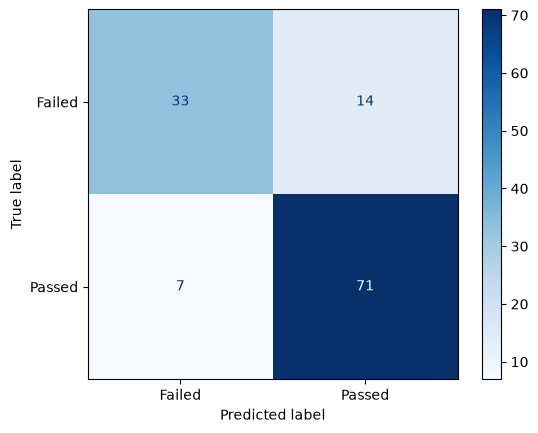

In [5]:
predictions = model.predict(X_test)
print(f"Training accuracy: {model.score(X_train, y_train):.3f}")
print(f"Test accuracy:     {accuracy_score(y_test, predictions):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["Failed", "Passed"], cmap="Blues")
plt.show()

## 5. One pipeline, one object

`ColumnTransformer` sends each group of columns through its own steps, and `Pipeline` puts the classifier after them. The result behaves as a single model: `fit` runs every step on the training rows, and `predict` repeats the same steps on new rows.

The test accuracy is 0.832, against a baseline of 0.624. The training accuracy is 0.779, lower than the test accuracy. That is the opposite of what Session 0 showed, and the next cell explains it.

> **Pause:** the test score is higher than the training score. Is the model better on unseen students? Decide before moving on.

In [6]:
scores = cross_val_score(model, X, y, cv=5)
print("Fold accuracies:", scores.round(3))
print(f"Mean {scores.mean():.3f}, standard deviation {scores.std():.3f}")

Fold accuracies: [0.72 0.81 0.78 0.8  0.85]
Mean 0.792, standard deviation 0.043


## 6. How much should one split be trusted?

**Cross-validation** repeats the experiment on five different splits and reports the spread. We pass the whole pipeline to `cross_val_score`, so the imputer, scaler and encoder are refitted on each fold's training rows and never see its validation rows.

The five accuracies are 0.72, 0.81, 0.78, 0.80 and 0.85, with a mean of 0.792 and a standard deviation of 0.043. Our single test score of 0.832 sits inside that range, and so does the training score. With 125 test students, one split can move the score by several points: in this case it landed on the easier side. So the answer to the pause question is no. The model is not better on new students than on old ones; this particular test set was a little easier.

Notice that accuracy of about 0.79 is well above the 0.624 baseline but far from perfect. That fits Session 1's finding that the features overlap heavily.

In [7]:
leaked = df.copy()
leaked["certificate_issued"] = np.where(leaked["passed"] == 1, "Yes", "No")
print(pd.crosstab(leaked["passed"].map({0: "failed", 1: "passed"}), leaked["certificate_issued"]))

certificate_issued   No  Yes
passed                      
failed              188    0
passed                0  312


## 7. Leakage: the model that looks perfect

Suppose the table also had a `certificate_issued` column. Certificates go out after final grades are known, so it is "Yes" for every student who passed and "No" for everyone else. The table above shows the match: it is the target under another name.

> **Pause:** we add this column and train the same pipeline. What accuracy do you expect?

In [8]:
Xl = leaked[numeric_features + categorical_features + ["certificate_issued"]]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xl, leaked["passed"], test_size=0.25, stratify=leaked["passed"], random_state=SEED)

leaky_preprocessing = ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features + ["certificate_issued"])])
leaky_model = Pipeline([("preprocessing", leaky_preprocessing), ("classifier", LogisticRegression(max_iter=1000, random_state=SEED))])
leaky_model.fit(Xl_train, yl_train)
print(f"Test accuracy without the certificate column: {accuracy_score(y_test, predictions):.3f}")
print(f"Test accuracy with the certificate column:    {leaky_model.score(Xl_test, yl_test):.3f}")

Test accuracy without the certificate column: 0.832
Test accuracy with the certificate column:    1.000


Without the column, the test accuracy is 0.832. With it, the same pipeline scores 1.000.

Nothing in the code is wrong. The split is random, preprocessing is fitted on training rows only, and the score is measured on unseen students. The score is still worthless, because the column doesn't exist when the prediction is needed: you can't use the certificate to predict who will pass when the certificates are only issued afterwards. The model learned to read the answer sheet instead of the student.

For every feature, ask: **would this value be known at the moment the prediction has to be made?** The same question catches several other kinds of leakage:

- a field recorded after the outcome, like this one;
- statistics computed on the whole dataset before splitting;
- the same person or machine appearing in both training and test data (the duplicate row from Session 1 was a small case of this);
- tuning many times against the test score, which Session 4 deals with.

A score that looks too good is a reason to investigate. Real models on messy data rarely reach 1.000.

## The checklist

1. Clean what Session 1 found (duplicates, impossible values) **before** splitting.
2. Split, and put the test set away.
3. Fit every imputer, scaler and encoder on the training set only. A `Pipeline` does this for you.
4. Use the whole pipeline inside cross-validation.
5. For each feature, ask whether it would exist at prediction time.
6. If a score looks too good, find out why before celebrating.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The formulas behind the steps

Median imputation replaces a missing value with the median of the observed training values. Standardisation turns a value $x$ into

$$
z=\frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}},
$$

with the mean and standard deviation taken from the training set. One-hot encoding turns a category into a vector with a single 1, for example CS becomes $[0,1,0]$ in the column order Business, CS, Engineering.

## Why not fit the scaler on everything?

Fitting on all rows before the split lets the test rows influence the mean and spread the model sees. For plain scaling the effect is usually small, so it is easy to dismiss. For steps that look at the target, such as choosing the features most correlated with it, the effect can be large: you can pick "good" features from pure noise and then score well on a test set that helped choose them. Putting every step in a `Pipeline` removes the temptation, because the pipeline can only be fitted on the rows you give it.

## Missing-value indicators

Sometimes the fact that a value is missing carries information, for instance if weaker students are less likely to hand in their records. `SimpleImputer(add_indicator=True)` adds a 0/1 column marking which values were filled in, so the model can use that signal. In our table the gaps are random, so it would not help here.

## Time and leakage

When the rows have dates, a random split can put the future in the training set and the past in the test set. The fairer split trains on earlier rows and tests on later ones, which is how the model will be used.